# Financial Market & Sector Analysis: Nifty 50 vs. Sectoral Indices
### Quantitative Risk, Beta ($\beta$), Correlation ($r$), and Volatility Modeling of Indian Equity Sectors

**Benchmark:** Nifty 50 Index (`^NSEI`)  
**Sector Indices:** Bank Nifty (`^NSEBANK`), Nifty IT (`^CNXIT`), Auto proxy (`BAJAJ-AUTO.NS`), and Nifty Pharma (`^CNXPHARMA`)  

---
## Executive Summary & Theoretical Framework
This notebook presents an end-to-end quantitative framework to analyze relative sensitivity, diversification potential, and risk-adjusted returns of major sector indices relative to the broad Indian equity benchmark (Nifty 50). The Yahoo Finance Nifty Auto index ticker (`^CNXAUTO`) is no longer published, so the Auto sector is represented by the valid proxy `BAJAJ-AUTO.NS` in this analysis.

### Key Financial Metrics & Formulas:
1. **Sector Beta ($\beta$):** Measures systemic market risk & sensitivity:
   $$\beta_i = \frac{\text{Cov}(R_i, R_m)}{\text{Var}(R_m)}$$
   - $\beta > 1.0$: Aggressive / High-Beta Sector (amplifies benchmark moves).
   - $\beta < 1.0$: Defensive / Low-Beta Sector (provides downside protection).

2. **Pearson Correlation Coefficient ($r$):** Measures linear co-movement:
   $$r_{i, m} = \frac{\text{Cov}(R_i, R_m)}{\sigma_i \sigma_m}$$

3. **Annualized Volatility ($\sigma_{ann}$):** Standard deviation scaled to trading days (252):
   $$\sigma_{ann} = \sigma_{daily} \times \sqrt{252}$$

4. **Sharpe Ratio (Annualized):** Risk-adjusted excess return over risk-free rate ($R_f = 6.5\%$). The code uses the annualized mean excess-return version for daily-return comparison, while the CAGR form is a common summary shorthand:
   $$\text{Sharpe}_{\text{annualized daily}} = \frac{(\bar{R}_{daily} - R_{f,daily}) \times 252}{\sigma_{daily} \sqrt{252}}$$
   $$\text{Sharpe}_{\text{CAGR shorthand}} = \frac{\text{CAGR} - R_f}{\sigma_{ann}}$$

5. **Maximum Drawdown (Max DD):** Peak-to-trough decline over the observation window:
   $$\text{Max DD} = \min_t \left( \frac{P_t - P_{peak}}{P_{peak}} \right)$$

In [1]:
# Step 1: Environment Setup & Library Imports
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import openpyxl
import warnings
warnings.filterwarnings('ignore')

# Visual styling settings
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Helvetica'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 1.0
print('Libraries successfully imported!')

Libraries successfully imported!


## Data

In [ ]:
# Step 2: Historical Data Extraction via Yahoo Finance API
from pathlib import Path

START = "2024-10-01"
END = "2026-10-01"

tickers = {
    'Nifty50': '^NSEI',
    'Bank': '^NSEBANK',
    'IT': '^CNXIT',
    'Auto': 'BAJAJ-AUTO.NS',  # '^CNXAUTO' is no longer available from Yahoo Finance; use an Auto-sector proxy.
    'Pharma': '^CNXPHARMA'
}
TICKERS = list(tickers.values())

print(f'Fetching historical data from {START} to {END}...')
raw_data = yf.download(TICKERS, start=START, end=END, auto_adjust=True)["Close"]

mapping = {v: k for k, v in tickers.items()}
df_prices = raw_data.rename(columns=mapping)[['Nifty50', 'Bank', 'IT', 'Auto', 'Pharma']].dropna()

prices_path = Path('../data/prices_snapshot.csv')
prices_path.parent.mkdir(parents=True, exist_ok=True)
df_prices.to_csv(prices_path)
print(f'Saved {len(df_prices)} price rows to {prices_path}')

print(f'Data ingestion complete. Total trading days: {len(df_prices)}')
df_prices.tail()

Fetching historical data for period = 2y...



[                       0%                       ]


[*******************   40%                       ]  2 of 5 completed


[**********************60%****                   ]  3 of 5 completed


[**********************80%*************          ]  4 of 5 completed


[*********************100%***********************]  5 of 5 completed

Data ingestion complete. Total trading days: 473


Ticker,Nifty50,Bank,IT,Auto,Pharma
Date,,,,,
2026-07-13,24211.000000,58131.449219,29015.849609,26981.500000,25643.349609
2026-07-14,24052.050781,57462.300781,28724.750000,26547.500000,25907.099609
2026-07-15,24078.500000,57757.851562,28532.250000,26645.099609,26003.599609
2026-07-16,24072.750000,57582.250000,28722.599609,26767.550781,26008.050781
2026-07-17,24334.300781,58521.398438,29226.599609,27099.750000,25645.000000


## Returns

In [ ]:
df_returns = df_prices.pct_change().dropna()
df_returns

## Beta & Correlation

In [ ]:
# Step 3: Quantitative Metrics Calculation Framework
rf_annual = 0.065  # 6.5% Indian 10Y Benchmark G-Sec yield
rf_daily = rf_annual / 252
benchmark = 'Nifty50'
sectors = ['Bank', 'IT', 'Auto', 'Pharma']

cov_matrix = df_returns.cov()
var_benchmark = df_returns[benchmark].var()
corr_matrix = df_returns.corr()

metrics = {}
for col in [benchmark] + sectors:
    beta = cov_matrix.loc[col, benchmark] / var_benchmark
    corr = corr_matrix.loc[col, benchmark]
    metrics[col] = {
        'Beta (β)': round(beta, 3),
        'Correlation (r)': round(corr, 3)
    }

--- QUANTITATIVE METRICS SUMMARY ---


,Beta (β),Correlation (r),CAGR (%),Ann. Volatility (%),Daily Volatility (%),Sharpe Ratio,Max Drawdown (%)
Nifty50,1.000,1.000,0.42,13.41,0.84,-0.39,-15.77
Bank,1.057,0.889,9.06,15.94,1.00,0.22,-18.32
IT,0.918,0.524,-15.09,23.49,1.48,-0.86,-43.97
Auto,1.258,0.817,4.18,20.65,1.30,-0.01,-28.23
Pharma,0.630,0.540,8.48,15.65,0.99,0.18,-16.69


## Volatility & Sharpe

In [ ]:
for col in [benchmark] + sectors:
    ret = df_returns[col]
    price = df_prices[col]

    cagr = ((price.iloc[-1] / price.iloc[0]) ** (252 / len(price)) - 1) * 100
    ann_vol = ret.std() * np.sqrt(252) * 100
    daily_vol = ret.std() * 100
    sharpe = ((ret.mean() - rf_daily) * 252) / (ret.std() * np.sqrt(252))

    metrics[col].update({
        'CAGR (%)': round(cagr, 2),
        'Ann. Volatility (%)': round(ann_vol, 2),
        'Daily Volatility (%)': round(daily_vol, 2),
        'Sharpe Ratio': round(sharpe, 2)
    })

## Drawdown

In [ ]:
for col in [benchmark] + sectors:
    ret = df_returns[col]
    cum = (1 + ret).cumprod()
    dd = (cum - cum.cummax()) / cum.cummax()
    max_dd = dd.min() * 100
    metrics[col]['Max Drawdown (%)'] = round(max_dd, 2)

In [ ]:
df_metrics_summary = pd.DataFrame(metrics).T
print('--- QUANTITATIVE METRICS SUMMARY ---')
df_metrics_summary

## Plots

findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


...

findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


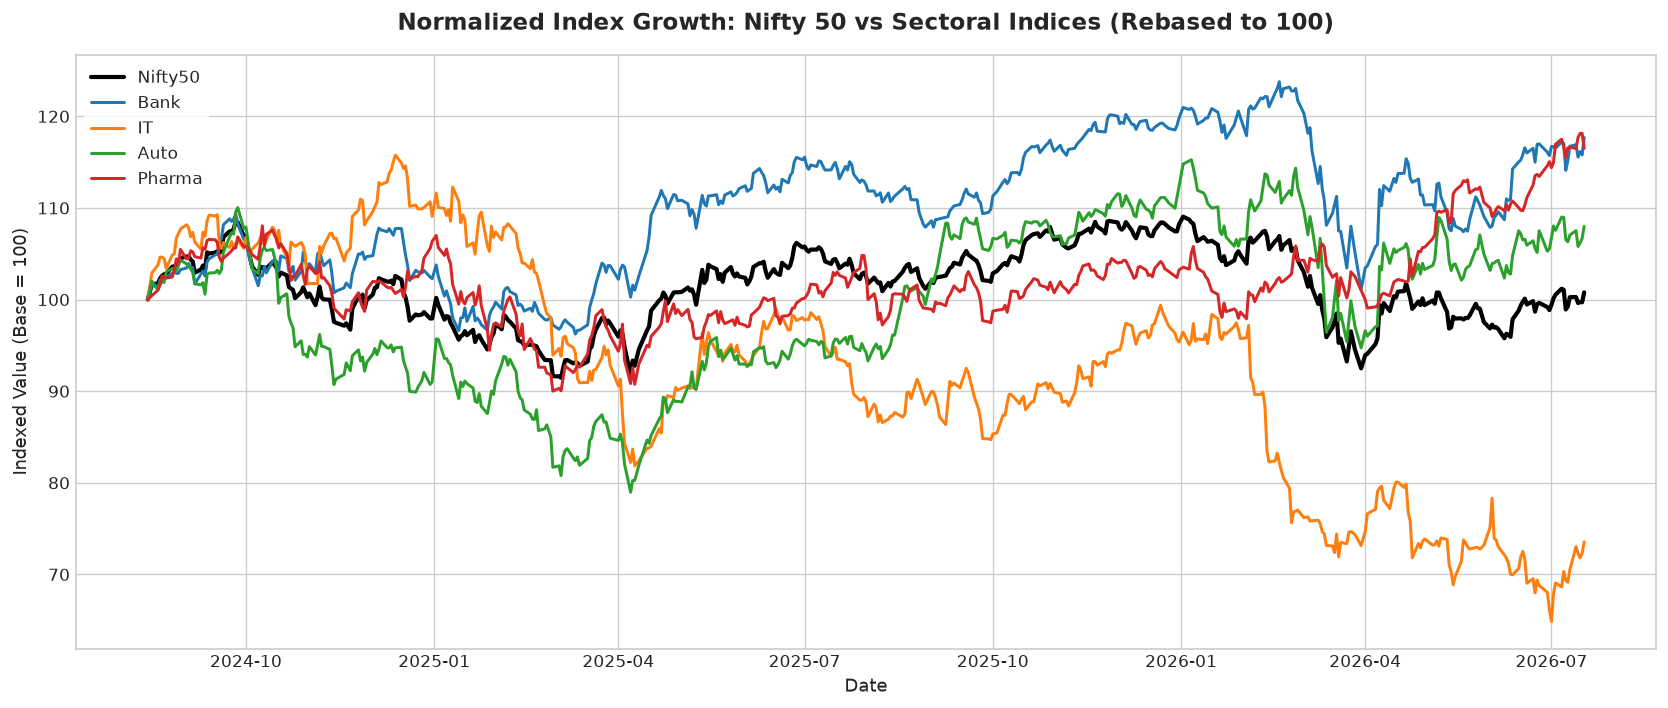

In [4]:
# Step 4 Visual 1: Cumulative Normalized Price Performance Chart
df_normalized = (df_prices / df_prices.iloc[0]) * 100

plt.figure(figsize=(14, 6), dpi=120)
colors = {'Nifty50': '#000000', 'Bank': '#1f77b4', 'IT': '#ff7f0e', 'Auto': '#2ca02c', 'Pharma': '#d62728'}
linewidths = {'Nifty50': 2.5, 'Bank': 1.8, 'IT': 1.8, 'Auto': 1.8, 'Pharma': 1.8}

for col in df_normalized.columns:
    plt.plot(df_normalized.index, df_normalized[col], label=col, color=colors[col], linewidth=linewidths[col])

plt.title('Normalized Index Growth: Nifty 50 vs Sectoral Indices (Rebased to 100)', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Indexed Value (Base = 100)', fontsize=11)
plt.xlabel('Date', fontsize=11)
plt.legend(frameon=True, facecolor='white', edgecolor='none', fontsize=10)
plt.tight_layout()
plt.show()

findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


...

findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


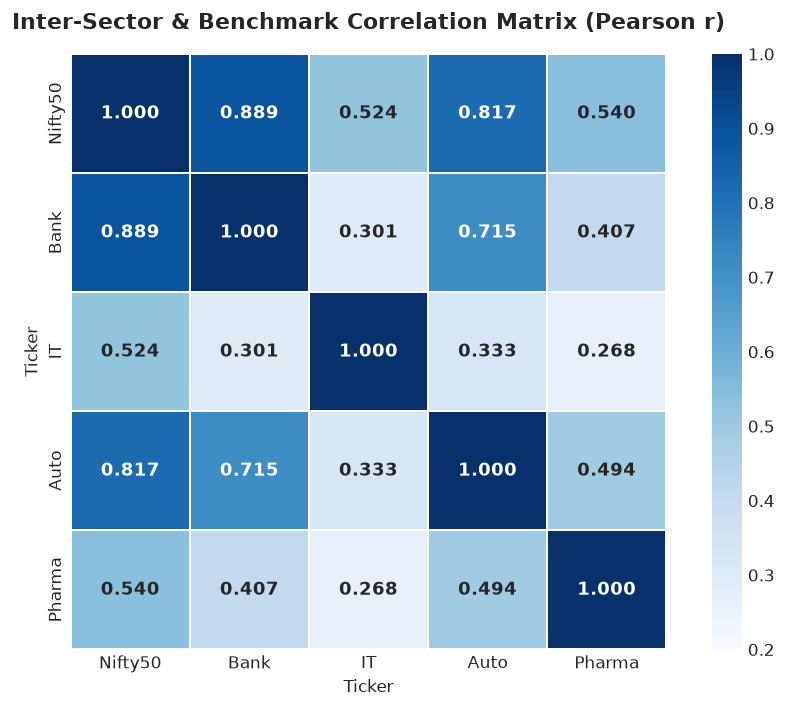

In [5]:
# Step 4 Visual 2: Inter-Sector Correlation Matrix Heatmap
plt.figure(figsize=(8, 6), dpi=120)
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='Blues', vmin=0.2, vmax=1.0, cbar=True, 
            linewidths=1.0, square=True, annot_kws={'size': 11, 'weight': 'bold'})
plt.title('Inter-Sector & Benchmark Correlation Matrix (Pearson r)', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


...

findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


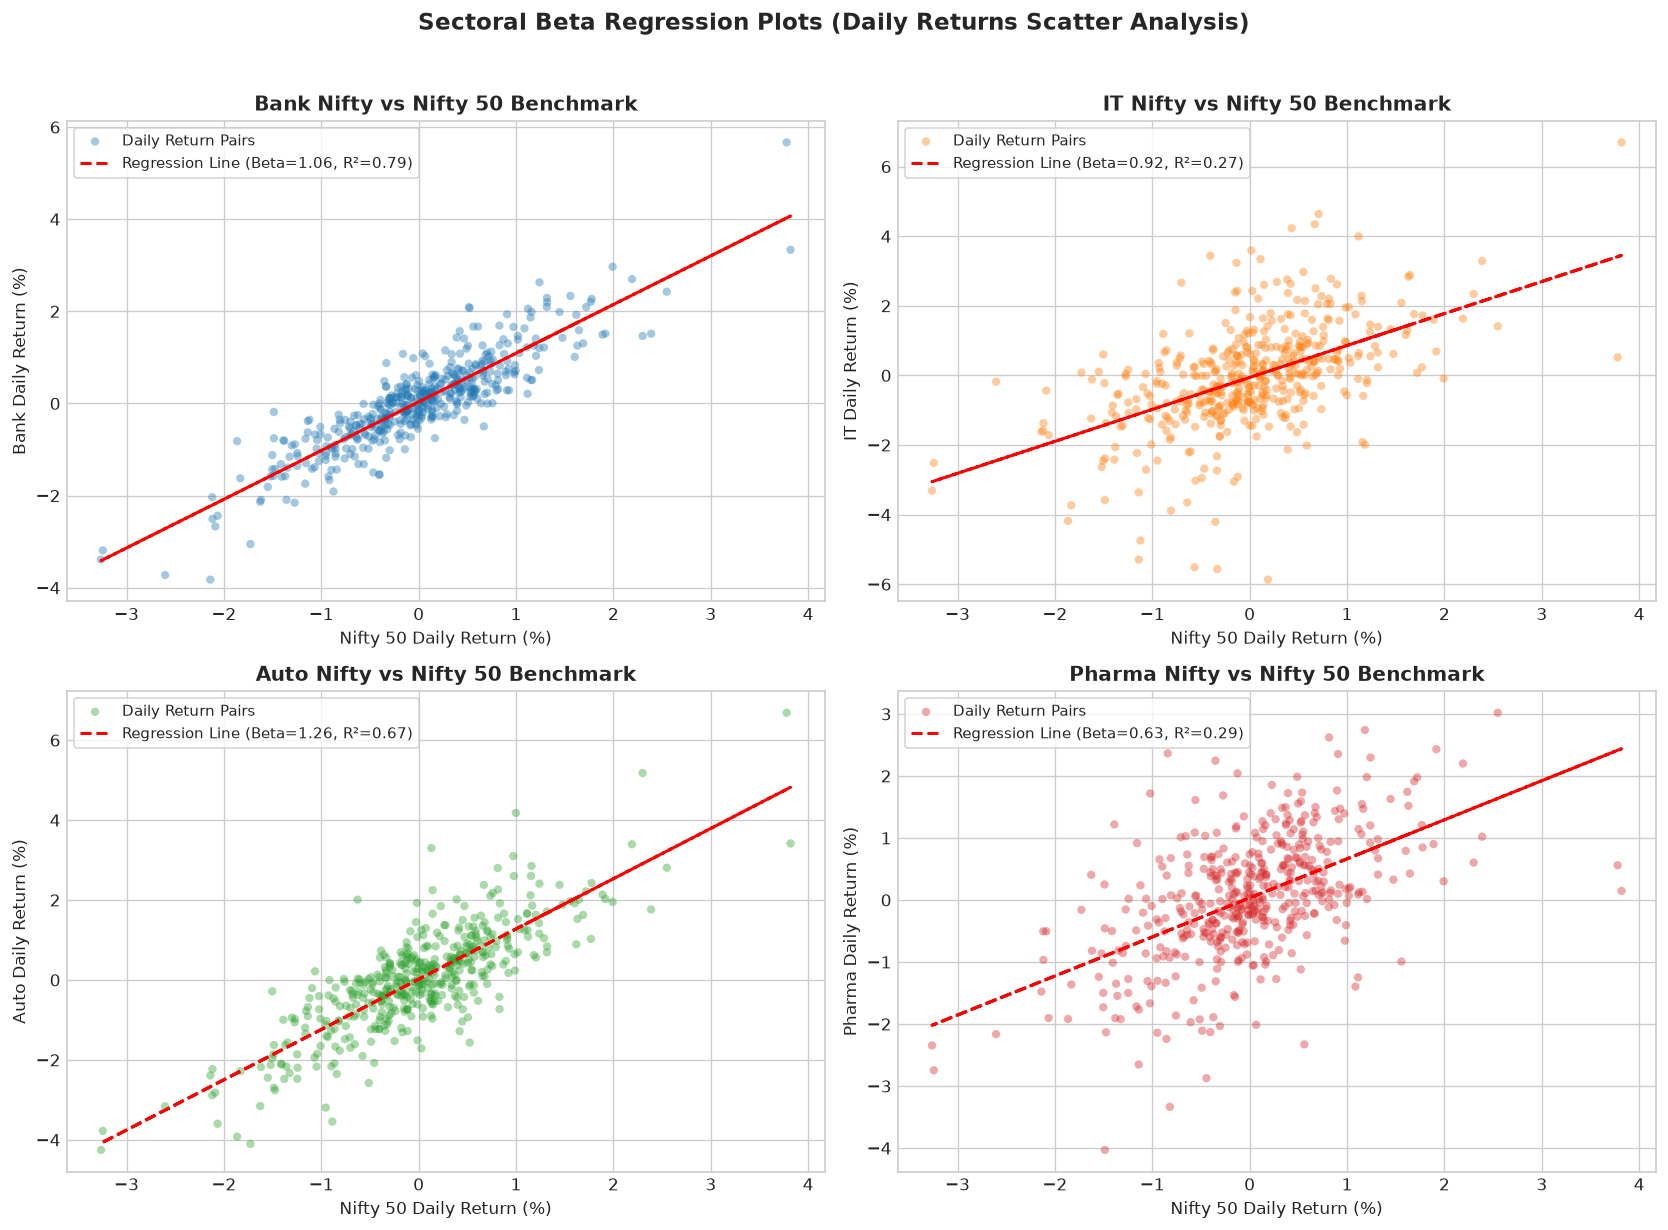

In [6]:
# Step 4 Visual 3: Sector Daily Returns Scatter Plots & Beta Linear Regression Lines
fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=120)
axes = axes.flatten()

for idx, sector in enumerate(sectors):
    ax = axes[idx]
    x = df_returns['Nifty50'] * 100
    y = df_returns[sector] * 100
    
    # Regression line
    slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
    
    ax.scatter(x, y, alpha=0.4, color=colors[sector], edgecolors='none', s=25, label='Daily Return Pairs')
    ax.plot(x, intercept + slope * x, color='red', linestyle='--', linewidth=1.8, 
            label=f'Regression Line (Beta={slope:.2f}, R²={r_value**2:.2f})')
    
    ax.set_title(f'{sector} Nifty vs Nifty 50 Benchmark', fontsize=12, fontweight='bold')
    ax.set_xlabel('Nifty 50 Daily Return (%)', fontsize=10)
    ax.set_ylabel(f'{sector} Daily Return (%)', fontsize=10)
    ax.legend(loc='upper left', frameon=True, fontsize=9)

plt.suptitle('Sectoral Beta Regression Plots (Daily Returns Scatter Analysis)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


...

findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


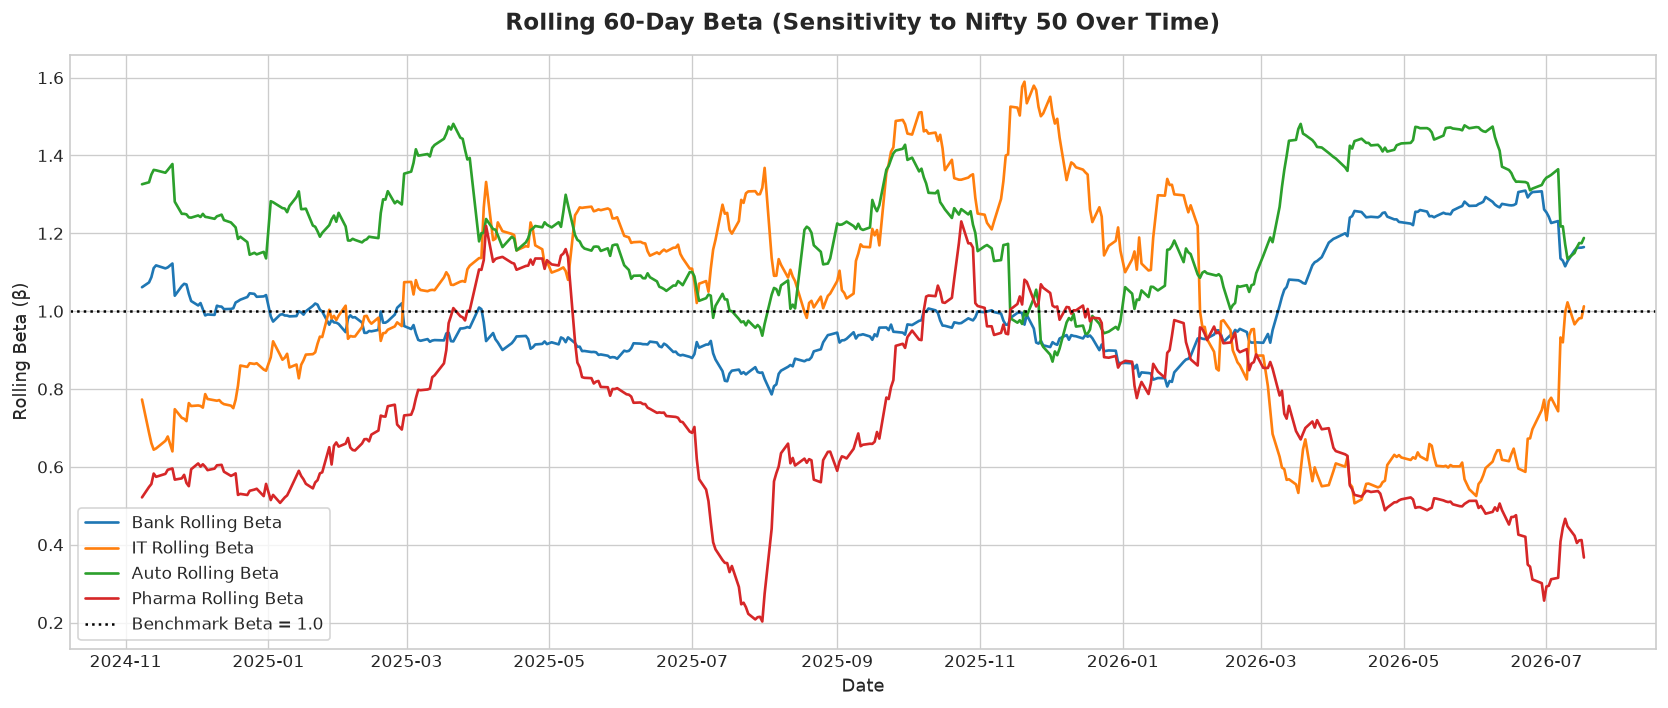

In [7]:
# Step 4 Visual 4: Rolling 60-Day Dynamic Beta Analysis
rolling_window = 60
rolling_beta = pd.DataFrame(index=df_returns.index)

for sector in sectors:
    cov_roll = df_returns[sector].rolling(rolling_window).cov(df_returns['Nifty50'])
    var_roll = df_returns['Nifty50'].rolling(rolling_window).var()
    rolling_beta[sector] = cov_roll / var_roll

plt.figure(figsize=(14, 6), dpi=120)
for sector in sectors:
    plt.plot(rolling_beta.index, rolling_beta[sector], label=f'{sector} Rolling Beta', color=colors[sector], linewidth=1.6)

plt.axhline(1.0, color='black', linestyle=':', linewidth=1.5, label='Benchmark Beta = 1.0')
plt.title('Rolling 60-Day Beta (Sensitivity to Nifty 50 Over Time)', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Rolling Beta (β)', fontsize=11)
plt.xlabel('Date', fontsize=11)
plt.legend(frameon=True, facecolor='white', fontsize=10)
plt.tight_layout()
plt.show()

findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


...

findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica


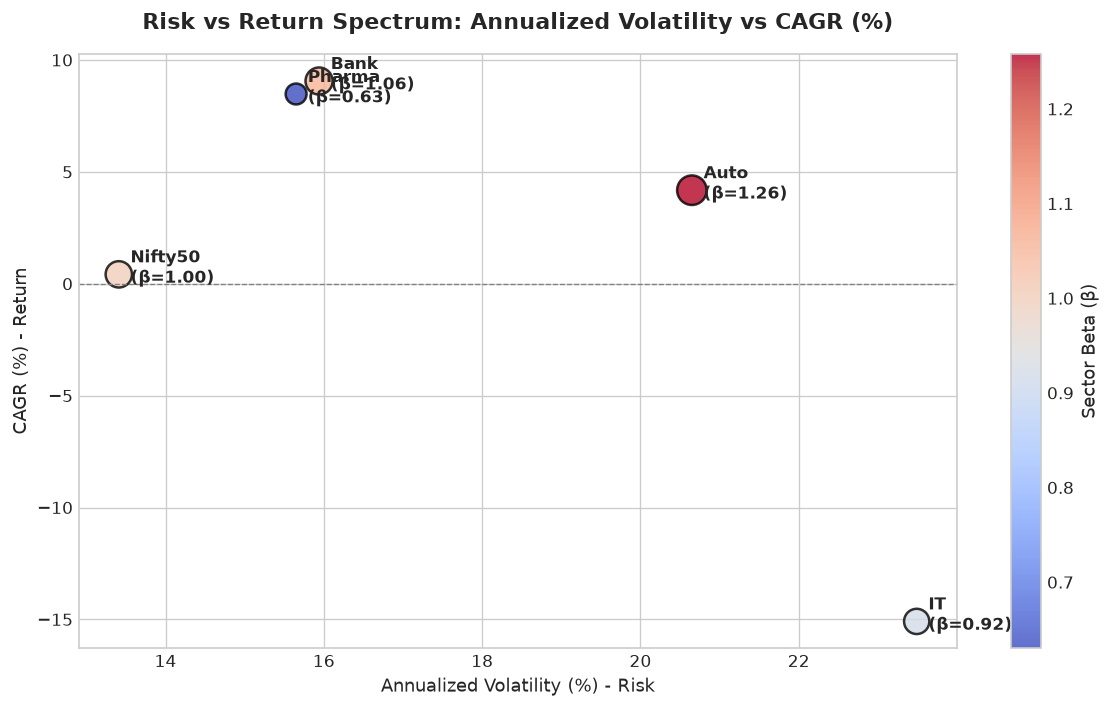

In [8]:
# Step 4 Visual 5: Risk (Volatility) vs Return Bubble Chart
plt.figure(figsize=(10, 6), dpi=120)

x_vol = df_metrics_summary['Ann. Volatility (%)']
y_ret = df_metrics_summary['CAGR (%)']
labels = df_metrics_summary.index
betas = df_metrics_summary['Beta (β)']

scatter = plt.scatter(x_vol, y_ret, s=betas*250, c=betas, cmap='coolwarm', alpha=0.8, edgecolors='black', linewidth=1.5)
cbar = plt.colorbar(scatter)
cbar.set_label('Sector Beta (β)', fontsize=11)

for i, label in enumerate(labels):
    plt.annotate(f'{label}\n(β={betas[i]:.2f})', (x_vol[i], y_ret[i]), xytext=(7, -5), 
                 textcoords='offset points', fontsize=10, fontweight='bold')

plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.title('Risk vs Return Spectrum: Annualized Volatility vs CAGR (%)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Annualized Volatility (%) - Risk', fontsize=11)
plt.ylabel('CAGR (%) - Return', fontsize=11)
plt.tight_layout()
plt.show()

In [ ]:
# Step 5: Save Structured Excel Workbook
output_filename = '../data/market_sector_analysis.xlsx'
print(f'Exporting financial dataset to {output_filename}...')

with pd.ExcelWriter(output_filename, engine='openpyxl') as writer:
    df_metrics_summary.to_excel(writer, sheet_name='Executive_Summary')
    df_prices.to_excel(writer, sheet_name='Raw_Prices')
    (df_returns * 100).to_excel(writer, sheet_name='Daily_Returns_%')
    corr_matrix.round(4).to_excel(writer, sheet_name='Correlation_Matrix')

print('Notebook analysis complete! Dataset exported successfully.')

Exporting financial dataset to Market_Sector_Analysis.xlsx...


Notebook analysis complete! Dataset exported successfully.
